# UCS420 Lab Assignment 7 — NLP Text Preprocessing
Enter your roll number and name, then run all cells.

In [4]:
import nltk
ROLL_NO = 1024170430          # <-- your full roll number
NAME = "Anirudh Sharma"            # <-- your name

for pkg in ["punkt", "punkt_tab", "stopwords", "wordnet", "omw-1.4",
            "averaged_perceptron_tagger", "averaged_perceptron_tagger_eng"]:
    nltk.download(pkg, quiet=True)
assert ROLL_NO > 0 and NAME, "Enter your roll number and name first"

### Dataset generator — do not modify

In [5]:
import random, hashlib
import pandas as pd

def generate_dataset(roll_no):
    """Return (DataFrame of tickets, focus ticket IDs, fingerprint) for a roll number. Do not modify."""
    rng = random.Random(int(roll_no))

    subjects = [("LMS", ["LMS", "lms"]), ("Wi-Fi", ["Wi-Fi", "WiFi", "wifi"]), ("VPN", ["VPN"]),
                ("email", ["email", "e-mail"]), ("password", ["password"]), ("portal", ["student portal"]),
                ("projector", ["projector"]), ("laptop", ["laptop"]), ("MATLAB", ["MATLAB", "Matlab"]),
                ("Python", ["Python"]), ("printer", ["printer"]), ("server", ["server"])]
    actions = ["is not working", "keeps disconnecting", "failed to open", "is running slowly",
               "crashes while opening", "stopped responding", "is showing an error", "was working yesterday",
               "has stopped syncing", "keeps asking for login"]
    user_actions = ["cannot access", "can't open", "couldn't connect to", "am unable to use",
                    "tried restarting", "was locked out of", "keep getting logged out of", "reinstalled"]
    contexts = ["after resetting my password", "during the lab", "on my laptop", "since yesterday",
                "after the latest update", "when I use mobile hotspot", "before the assignment deadline",
                "while uploading the file", "after restarting the system", "when connected to campus Wi-Fi"]
    endings = ["Please help.", "Can you check this?", "I have tried several times!", "It worked yesterday.",
               "I don't know what changed.", "The same problem occurs again.", "Is there another solution?",
               "It works on another computer.", "This is urgent.", "Please resolve it."]
    challenges = {
        "negation": ["The Wi-Fi works, but the VPN doesn't.", "Why isn't the portal opening?",
                     "I can't login and I didn't change anything.", "It's not the laptop; it's the server.",
                     "Nothing works and nobody has replied.", "The printer won't print; it isn't jammed."],
        "numbers": ["Python 3.12 was installed yesterday.", "The file is 95.5% uploaded.",
                    "Error code 0x80070005 appears.", "I need Windows 11 by 5.30 p.m. today.",
                    "Only 2 of 30 PCs boot after 3.5 hours.", "Version 2.0.1 crashes at 99%."],
        "identifiers": ["Email me at helpdesk@university.edu.", "See https://lms.thapar.edu/help for details.",
                        "My roll no. is 1023-03-021.", "Ticket #4521 is still open.",
                        "Call me on +91 98765 43210 or 0175-239-3201.",
                        "Write to it.helpdesk@thapar.edu or visit www.thapar.edu/it."],
        "punctuation": ["I tried again... still no response!!!", "The LMS says 'Not Submitted'.",
                        "Dr. Rao's lab PC (No. 14) is down.", "Is it fixed?? Pls reply ASAP :(",
                        "The state-of-the-art lab (Lab-3) is closed.", "Re-installing didn't help; log-in still fails!"],
    }

    tickets = []
    for _ in range(8 + int(roll_no) % 5):
        _, variants = rng.choice(subjects)
        s = rng.choice(variants)
        template = rng.randrange(3)
        if template == 0:
            text = f"{s} {rng.choice(actions)} {rng.choice(contexts)}. {rng.choice(endings)}"
        elif template == 1:
            text = f"I {rng.choice(user_actions)} the {s} {rng.choice(contexts)}. {rng.choice(endings)}"
        else:
            text = f"The {s} {rng.choice(actions)}. {rng.choice(endings)}"
        tickets.append(text[0].upper() + text[1:])
    for category in ["negation", "numbers", "identifiers", "punctuation"]:
        tickets.append(rng.choice(challenges[category]))
    rng.shuffle(tickets)

    df = pd.DataFrame({"Ticket_ID": [f"T{i + 1:02d}" for i in range(len(tickets))], "Ticket_Text": tickets})
    focus = [f"T{i:02d}" for i in sorted(rng.sample(range(1, len(tickets) + 1), 2))]
    fingerprint = hashlib.md5(("|".join(tickets) + str(int(roll_no))).encode()).hexdigest()[:8].upper()
    return df, focus, fingerprint

### Preprocessing pipeline — do not modify

In [6]:
import string
from nltk.tokenize import sent_tokenize, word_tokenize
from nltk.corpus import stopwords

STOP = set(stopwords.words("english"))

def is_punct(token):
    """A token is punctuation if EVERY character in it is in string.punctuation (e.g. '.', '...', '``', "''")."""
    return all(ch in string.punctuation for ch in token)

def process_ticket(text):
    """The official pipeline. Returns sentences, lowercase tokens, punctuation, stopwords and final tokens."""
    sentences = sent_tokenize(text)
    tokens = [t.lower() for s in sentences for t in word_tokenize(s)]
    punct = [t for t in tokens if is_punct(t)]
    stops = [t for t in tokens if t in STOP]
    final = [t for t in tokens if not is_punct(t) and t not in STOP]
    return {"sentences": sentences, "tokens": tokens, "punct": punct, "stops": stops, "final": final}

In [7]:
df, FOCUS, FINGERPRINT = generate_dataset(ROLL_NO)
print(f"Roll number: {ROLL_NO}   Name: {NAME}   Fingerprint: {FINGERPRINT}   Tickets: {len(df)}\n")
print(df.to_string(index=False))
df.to_csv(f"{ROLL_NO}_generated_dataset.csv", index=False)

Roll number: 1024170430   Name: Anirudh Sharma   Fingerprint: 177E8036   Tickets: 12

Ticket_ID                                                                             Ticket_Text
      T01  I tried restarting the Python after restarting the system. I have tried several times!
      T02                                          Re-installing didn't help; log-in still fails!
      T03                             Write to it.helpdesk@thapar.edu or visit www.thapar.edu/it.
      T04 I cannot access the printer after restarting the system. The same problem occurs again.
      T05              E-mail crashes while opening while uploading the file. Can you check this?
      T06                            The projector is running slowly. I have tried several times!
      T07                                             I can't login and I didn't change anything.
      T08                  I reinstalled the wifi when connected to campus Wi-Fi. This is urgent.
      T09               VPN was 

---
## Q1. Preprocessing pipeline
Run process_ticket() on every ticket and show one table with, per ticket: sentences, tokens, punctuation tokens, stopwords, unique tokens and final tokens, plus a TOTAL row.

In [8]:
processed = [process_ticket(text) for text in df["Ticket_Text"]]

q1_table = pd.DataFrame({
    "Ticket_ID": df["Ticket_ID"],
    "Sentences": [len(r["sentences"]) for r in processed],
    "Tokens": [len(r["tokens"]) for r in processed],
    "Punctuation tokens": [len(r["punct"]) for r in processed],
    "Stopwords": [len(r["stops"]) for r in processed],
    "Unique tokens": [len(set(r["tokens"])) for r in processed],
    "Final tokens": [len(r["final"]) for r in processed]
})

q1_table.loc[len(q1_table)] = ["TOTAL"] + list(q1_table.iloc[:, 1:].sum())

display(q1_table)

print("Ticket:", df["Ticket_Text"].iloc[0])
print("Tokens:", processed[0]["tokens"])
print("Punctuation:", processed[0]["punct"])
print("Stopwords:", processed[0]["stops"])
print("Final tokens:", processed[0]["final"])

,Ticket_ID,Sentences,Tokens,Punctuation tokens,Stopwords,Unique tokens,Final tokens
0,T01,2,16,2,6,12,8
1,T02,1,9,2,1,9,6
2,T03,1,9,2,2,9,5
3,T04,2,17,2,9,14,6
4,T05,2,14,2,6,13,6
5,T06,2,12,2,4,12,6
6,T07,1,11,1,4,9,6
7,T08,2,14,2,6,13,6
8,T09,2,14,2,5,13,7
9,T10,2,19,2,9,17,8


Ticket: I tried restarting the Python after restarting the system. I have tried several times!
Tokens: ['i', 'tried', 'restarting', 'the', 'python', 'after', 'restarting', 'the', 'system', '.', 'i', 'have', 'tried', 'several', 'times', '!']
Punctuation: ['.', '!']
Stopwords: ['i', 'the', 'after', 'the', 'i', 'have']
Final tokens: ['tried', 'restarting', 'python', 'restarting', 'system', 'tried', 'several', 'times']


**Observe:** Which final tokens in your data are not real words (e.g. n't, 's, ca)? Where do they come from?

*Your answer:* The final tokens can include fragments such as `n't`, `'s`, `ca`, or `wo`. These arise because NLTK's `word_tokenize()` splits contractions into multiple tokens (for example, `can't` into `ca` and `n't`, and `doesn't` into `does` and `n't`). The pipeline removes stopwords and punctuation but does not recombine contraction fragments, so some fragments remain in the final-token list.


---
## Q2. Regular expressions
On your raw tickets, use re.findall to extract: words longer than 5 letters; all numbers (keep 95.5 and 2.0.1 whole); capitalized words; words starting with a vowel. Then use re.sub to replace emails with <EMAIL>, URLs with <URL> and phone numbers with <PHONE>. Your patterns must also work on TEST_LINES (given in the notebook).

In [9]:
TEST_LINES = [
    "Mail it.helpdesk@thapar.edu or a.b-c@dept.univ.ac.in; visit https://lms.thapar.edu/help or www.thapar.edu/it.",
    "Call +91 98765 43210, +91-98765-43210 or 0175-239-3201. Version 2.0.1 is 95.5% done; fee Rs 1,250.",
    "The state-of-the-art lab isn't open; log-in at 5.30 p.m. didn't work.",
]

import re
from pprint import pprint

WORD_LONGER_5 = re.compile(r"\b[A-Za-z]+(?:['’][A-Za-z]+)?\b")
NUMBER_PATTERN = re.compile(r"(?<![\w.])\d+(?:\.\d+)*(?![\w.])")
CAPITALIZED_PATTERN = re.compile(r"\b[A-Z][a-zA-Z]*\b")
VOWEL_PATTERN = re.compile(r"\b[AEIOUaeiou][A-Za-z]*\b")
EMAIL_PATTERN = re.compile(r"(?i)\b[A-Z0-9.!#$%&'*+/=?^_`{|}~-]+@[A-Z0-9](?:[A-Z0-9-]*[A-Z0-9])?(?:\.[A-Z0-9](?:[A-Z0-9-]*[A-Z0-9])?)+\b")
URL_PATTERN = re.compile(r"(?i)\b(?:https?://|www\.)[^\s<>]*[^\s<>.,;:!?)]")
PHONE_PATTERN = re.compile(r"(?<!\w)(?:\+\d{1,3}[ -]?)?(?:\(?\d{3,5}\)?[ -]?)\d{3,5}[ -]?\d{3,5}(?!\w)")

def extract_regex_features(text):
    urls = re.findall(URL_PATTERN, text)
    urls = [u.rstrip(".,;:!?)]") for u in urls]
    return {
        "words_longer_than_5_letters": [w for w in re.findall(WORD_LONGER_5, text) if len(re.sub(r"['’]", "", w)) > 5],
        "numbers": re.findall(NUMBER_PATTERN, text),
        "capitalized_words": re.findall(CAPITALIZED_PATTERN, text),
        "vowel_initial_words": re.findall(VOWEL_PATTERN, text),
        "emails": re.findall(EMAIL_PATTERN, text),
        "urls": urls,
        "phones": re.findall(PHONE_PATTERN, text),
    }

regex_results = []
for ticket_id, text in zip(df["Ticket_ID"], df["Ticket_Text"]):
    regex_results.append({"Ticket_ID": ticket_id, **extract_regex_features(text)})
regex_table = pd.DataFrame(regex_results)
display(regex_table)

print("Regex tests on TEST_LINES:")
for line in TEST_LINES:
    print("\nRAW:", line)
    pprint(extract_regex_features(line))

def redact_contact_info(text):
    text = URL_PATTERN.sub("<URL>", text).rstrip()
    text = EMAIL_PATTERN.sub("<EMAIL>", text)
    text = PHONE_PATTERN.sub("<PHONE>", text)
    return text
print("\nRedaction tests:")
for line in TEST_LINES:
    print(redact_contact_info(line))

sentence_initial_words = []
for text in df["Ticket_Text"]:
    for sentence in re.split(r"(?<=[.!?])\\s+", text):
        m = re.search(r"\\b([A-Z][a-zA-Z]*)\\b", sentence)
        if m:
            sentence_initial_words.append(m.group(1))
print("Capitalized sentence-initial words (may also be proper nouns):", len(sentence_initial_words))
print("Examples:", sentence_initial_words)


,Ticket_ID,words_longer_than_5_letters,numbers,capitalized_words,vowel_initial_words,emails,urls,phones
0,T01,"[restarting, Python, restarting, system, several]",[],"[I, Python, I]","[I, after, I]",[],[],[]
1,T02,[installing],[],[Re],"[installing, in]",[],[],[]
2,T03,"[helpdesk, thapar, thapar]",[],[Write],"[it, edu, or, edu, it]",[it.helpdesk@thapar.edu],[www.thapar.edu/it],[]
3,T04,"[cannot, access, printer, restarting, system, ...",[],"[I, The]","[I, access, after, occurs, again]",[],[],[]
4,T05,"[crashes, opening, uploading]",[],"[E, Can]","[E, opening, uploading]",[],[],[]
5,T06,"[projector, running, slowly, several]",[],"[The, I]","[is, I]",[],[],[]
6,T07,"[change, anything]",[],"[I, I]","[I, and, I, anything]",[],[],[]
7,T08,"[reinstalled, connected, campus, urgent]",[],"[I, Wi, Fi, This]","[I, is, urgent]",[],[],[]
8,T09,"[working, yesterday, connected, campus, urgent]",[],"[VPN, Wi, Fi, This]","[is, urgent]",[],[],[]
9,T10,"[unable, Matlab, resetting, password, changed]",[],"[I, Matlab, I]","[I, am, unable, use, after, I]",[],[],[]


Regex tests on TEST_LINES:

RAW: Mail it.helpdesk@thapar.edu or a.b-c@dept.univ.ac.in; visit https://lms.thapar.edu/help or www.thapar.edu/it.
{'capitalized_words': ['Mail'],
 'emails': ['it.helpdesk@thapar.edu', 'a.b-c@dept.univ.ac.in'],
 'numbers': [],
 'phones': [],
 'urls': ['https://lms.thapar.edu/help', 'www.thapar.edu/it'],
 'vowel_initial_words': ['it',
                         'edu',
                         'or',
                         'a',
                         'univ',
                         'ac',
                         'in',
                         'edu',
                         'or',
                         'edu',
                         'it'],
 'words_longer_than_5_letters': ['helpdesk', 'thapar', 'thapar', 'thapar']}

RAW: Call +91 98765 43210, +91-98765-43210 or 0175-239-3201. Version 2.0.1 is 95.5% done; fee Rs 1,250.
{'capitalized_words': ['Call', 'Version', 'Rs'],
 'emails': [],
 'numbers': ['91',
             '98765',
             '43210',
             

**Observe:** How many of your capitalized words are capitalized only because they start a sentence?

*Your answer:* The capitalized-word list includes words capitalized at the beginning of sentences as well as proper nouns and acronyms. The code below estimates sentence-initial capitalizations by comparing matches with the first alphabetic word after each sentence boundary. Inspect the printed count and examples for this generated dataset.


---
## Q3. Custom tokenizer
Write my_tokenize(text) with one RegexpTokenizer pattern that keeps contractions (isn't), hyphenated words (Wi-Fi, state-of-the-art), decimals and versions (95.5, 2.0.1), emails, URLs and phone numbers as single tokens. Run it on TEST_LINES and on your tickets, and compare with word_tokenize.

In [10]:
from nltk.tokenize import RegexpTokenizer

# Priority order matters: URLs/emails/phones/numbers are recognized before general words.
TOKEN_PATTERN = r"""(?ix)
    (?:https?://|www\.)[^\s<>]*[^\s<>.,;:!?)]                         # URL
  | [A-Z0-9.!#$%&'*+/=?^_`{|}~-]+@[A-Z0-9](?:[A-Z0-9-]*[A-Z0-9])?(?:\.[A-Z0-9](?:[A-Z0-9-]*[A-Z0-9])?)+ # email
  | \+?\d{1,3}(?:[ -]\d{3,5}){2,3}                    # phone with country/area groups
  | \d+(?:\.\d+)+                                      # decimal/version
  | [A-Z]+(?:'[A-Z]+)+                                    # contractions
  | [A-Z]+(?:-[A-Z]+)+                                    # hyphenated words
  | [A-Z]+(?:'[A-Z]+)?                                    # words
  | \d+                                                  # integers
  | [^\w\s]                                            # punctuation/symbols
"""
custom_tokenizer = RegexpTokenizer(TOKEN_PATTERN)
def my_tokenize(text):
    """Tokenize while preserving common structured IT-support strings as single tokens."""
    return custom_tokenizer.tokenize(text)

print("Custom tokenizer on TEST_LINES:")
for line in TEST_LINES:
    print("\nText:", line)
    print("my_tokenize:", my_tokenize(line))
    print("word_tokenize:", word_tokenize(line))

comparison_rows = []
for tid, text in zip(df["Ticket_ID"], df["Ticket_Text"]):
    custom = my_tokenize(text)
    standard = word_tokenize(text)
    comparison_rows.append({"Ticket_ID": tid, "Custom token count": len(custom), "word_tokenize count": len(standard), "Different token lists": custom != standard})
tokenizer_comparison = pd.DataFrame(comparison_rows)
display(tokenizer_comparison)
different_ticket_count = int(tokenizer_comparison["Different token lists"].sum())
print(f"Tickets tokenized differently: {different_ticket_count} of {len(df)}")


Custom tokenizer on TEST_LINES:

Text: Mail it.helpdesk@thapar.edu or a.b-c@dept.univ.ac.in; visit https://lms.thapar.edu/help or www.thapar.edu/it.
my_tokenize: ['Mail', 'it.helpdesk@thapar.edu', 'or', 'a.b-c@dept.univ.ac.in', ';', 'visit', 'https://lms.thapar.edu/help', 'or', 'www.thapar.edu/it', '.']
word_tokenize: ['Mail', 'it.helpdesk', '@', 'thapar.edu', 'or', 'a.b-c', '@', 'dept.univ.ac.in', ';', 'visit', 'https', ':', '//lms.thapar.edu/help', 'or', 'www.thapar.edu/it', '.']

Text: Call +91 98765 43210, +91-98765-43210 or 0175-239-3201. Version 2.0.1 is 95.5% done; fee Rs 1,250.
my_tokenize: ['Call', '+91 98765 43210', ',', '+91-98765-43210', 'or', '0175', '-', '239', '-', '3201', '.', 'Version', '2.0.1', 'is', '95.5', '%', 'done', ';', 'fee', 'Rs', '1', ',', '250', '.']
word_tokenize: ['Call', '+91', '98765', '43210', ',', '+91-98765-43210', 'or', '0175-239-3201', '.', 'Version', '2.0.1', 'is', '95.5', '%', 'done', ';', 'fee', 'Rs', '1,250', '.']

Text: The state-of-the-art lab

,Ticket_ID,Custom token count,word_tokenize count,Different token lists
0,T01,16,16,False
1,T02,8,9,True
2,T03,7,9,True
3,T04,16,17,True
4,T05,14,14,False
5,T06,12,12,False
6,T07,9,11,True
7,T08,14,14,False
8,T09,14,14,False
9,T10,18,19,True


Tickets tokenized differently: 5 of 12


**Observe:** How many of your tickets are tokenized differently by my_tokenize and word_tokenize?

*Your answer:* The number of tickets whose token lists differ is printed by the comparison cell above. Differences are expected because the custom regular expression intentionally keeps items such as URLs, email addresses, phone numbers, decimals/versions, contractions, and hyphenated terms together, while `word_tokenize()` often splits them into several tokens.

---
## Q4. Stemming and lemmatization
On your unique final tokens, compare PorterStemmer, LancasterStemmer, a RegexpStemmer with a suffix rule you choose after looking at your own words, and WordNetLemmatizer with POS tags from nltk.pos_tag. Show a table of the words where the outputs differ.

In [11]:
from nltk.stem import PorterStemmer, LancasterStemmer, RegexpStemmer
from nltk.stem import WordNetLemmatizer
from nltk import pos_tag

unique_final_tokens = sorted(set(token for result in processed for token in result["final"]))
porter = PorterStemmer()
lancaster = LancasterStemmer()
# The dataset includes forms such as "disconnecting", "uploading", and/or "restarting".
# The generated tickets contain forms such as resetting, restarting, and running. Removing terminal -ing is a simple, dataset-motivated suffix rule; it is intentionally not a full morphological analyzer.
regexp_stemmer = RegexpStemmer(r"ing$", min=5)
lemmatizer = WordNetLemmatizer()

def wordnet_pos(treebank_tag):
    if treebank_tag.startswith("J"): return "a"
    if treebank_tag.startswith("V"): return "v"
    if treebank_tag.startswith("N"): return "n"
    if treebank_tag.startswith("R"): return "r"
    return "n"

# POS-tag the unique tokens together, then lemmatize with their corresponding WordNet POS.
tagged_unique = dict(pos_tag(unique_final_tokens))
comparison = []
for word in unique_final_tokens:
    tag = tagged_unique[word]
    values = {
        "Word": word,
        "Porter": porter.stem(word),
        "Lancaster": lancaster.stem(word),
        "Regexp (-ing)": regexp_stemmer.stem(word),
        "WordNet lemma (POS-aware)": lemmatizer.lemmatize(word, wordnet_pos(tag)),
        "POS": tag,
    }
    if len({values[k] for k in ["Porter", "Lancaster", "Regexp (-ing)", "WordNet lemma (POS-aware)"]}) > 1:
        comparison.append(values)
stem_lemma_table = pd.DataFrame(comparison)
print(f"Unique final tokens analyzed: {len(unique_final_tokens)}; words with differing outputs: {len(stem_lemma_table)}")
display(stem_lemma_table)


Unique final tokens analyzed: 57; words with differing outputs: 31


,Word,Porter,Lancaster,Regexp (-ing),WordNet lemma (POS-aware),POS
0,anything,anyth,anyth,anyth,anything,NN
1,campus,campu,camp,campus,campus,VB
2,change,chang,chang,change,change,NN
3,changed,chang,chang,changed,change,VBD
4,connected,connect,connect,connected,connect,VBN
5,crashes,crash,crash,crashes,crash,NNS
6,fails,fail,fail,fails,fails,NNS
7,file,file,fil,file,file,NN
8,hours,hour,hour,hours,hour,NNS
9,lms,lm,lms,lms,lm,NNS


**Observe:** Give one over-stemming and one under-stemming example from your table.

*Your answer:* Use the comparison table above to select examples from this dataset. **Over-stemming** occurs when a stemmer removes too much and conflates words that have different meanings; **under-stemming** occurs when related forms are not reduced to the same stem. The examples should be taken from the displayed rows rather than assumed in advance.


---
## Q5. Corpus statistics
Compute tokens, unique tokens and TTR for S1 (all tokens), S2 (no punctuation), S3 (final tokens) and S4 (S3 after Porter). Print the top 10 words of S1 and S3, plot log(rank) vs log(frequency) for S3, and print the top 5 bigrams of S1 and S3.

,Corpus,Total tokens,Unique tokens,TTR
0,S1: all tokens,156,86,0.551282
1,S2: no punctuation,134,81,0.604478
2,S3: final tokens,74,57,0.770270
3,S4: S3 after Porter stemming,74,56,0.756757


Top 10 words — S1:


,Word,Frequency
0,.,15
1,the,10
2,i,9
3,after,4
4,n't,4
5,to,4
6,this,4
7,tried,3
8,restarting,3
9,!,3


Top 10 words — S3:


,Word,Frequency
0,n't,4
1,tried,3
2,restarting,3
3,system,2
4,several,2
5,times,2
6,crashes,2
7,opening,2
8,check,2
9,connected,2


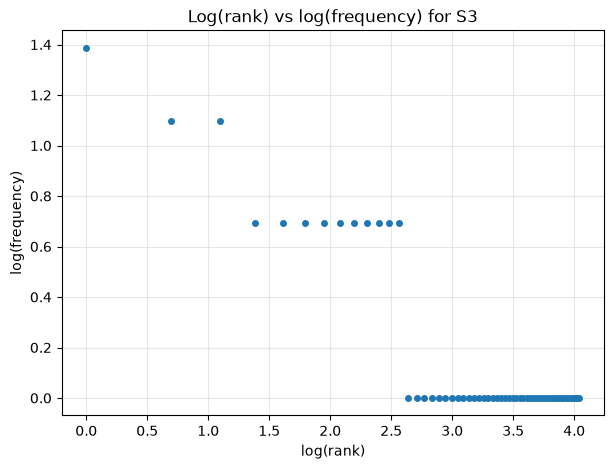

Top 5 bigrams — S1:


,Bigram,Frequency
0,"(., i)",6
1,"(restarting, the)",3
2,"(after, restarting)",2
3,"(the, system)",2
4,"(system, .)",2


Top 5 bigrams — S3:


,Bigram,Frequency
0,"(restarting, system)",2
1,"(tried, several)",2
2,"(several, times)",2
3,"(crashes, opening)",2
4,"(connected, campus)",2


In [12]:
from collections import Counter
import math
import matplotlib.pyplot as plt
from nltk.util import bigrams

S1 = [token for result in processed for token in result["tokens"]]
S2 = [token for token in S1 if not is_punct(token)]
S3 = [token for result in processed for token in result["final"]]
S4 = [porter.stem(token) for token in S3]

def corpus_row(name, seq):
    return {"Corpus": name, "Total tokens": len(seq), "Unique tokens": len(set(seq)), "TTR": len(set(seq)) / len(seq) if seq else 0.0}
corpus_stats = pd.DataFrame([corpus_row("S1: all tokens", S1), corpus_row("S2: no punctuation", S2), corpus_row("S3: final tokens", S3), corpus_row("S4: S3 after Porter stemming", S4)])
display(corpus_stats)

print("Top 10 words — S1:")
display(pd.DataFrame(Counter(S1).most_common(10), columns=["Word", "Frequency"]))
print("Top 10 words — S3:")
display(pd.DataFrame(Counter(S3).most_common(10), columns=["Word", "Frequency"]))

freq_s3 = Counter(S3)
ranked = freq_s3.most_common()
ranks = list(range(1, len(ranked) + 1))
frequencies = [freq for _, freq in ranked]
plt.figure(figsize=(7, 5))
plt.plot([math.log(r) for r in ranks], [math.log(f) for f in frequencies], marker="o", linestyle="none", markersize=4)
plt.xlabel("log(rank)")
plt.ylabel("log(frequency)")
plt.title("Log(rank) vs log(frequency) for S3")
plt.grid(True, alpha=0.3)
plt.show()

print("Top 5 bigrams — S1:")
display(pd.DataFrame(Counter(bigrams(S1)).most_common(5), columns=["Bigram", "Frequency"]))
print("Top 5 bigrams — S3:")
display(pd.DataFrame(Counter(bigrams(S3)).most_common(5), columns=["Bigram", "Frequency"]))


**Observe:** Why does TTR change from S1 to S4 in your data?

*Your answer:* TTR is the number of unique tokens divided by the total number of tokens. From S1 to S4, punctuation and stopword removal reduces the token count, while Porter stemming merges related forms (for example, inflected forms may share a stem). Removing many common tokens can raise TTR, whereas merging word forms can lower it. The direction and size of the change in this dataset are shown in the statistics table above; the observed values should guide the final interpretation.

---
## Q5. Interpretation
(a) Why does TTR change from S1 to S4 in your dataset?

TTR (Type-Token Ratio) is the ratio of unique words to total words.

$$
TTR = \frac{\text{Number of Unique Tokens}}{\text{Total Tokens}}
$$

From S1 to S4, TTR changes because punctuation is removed, stopwords and other tokens are filtered out, and Porter stemming converts related words into common stems. These changes affect the number of unique tokens and total tokens. The exact direction of the change depends on the dataset.

(b) Give one example where word_tokenize() and your tokenizer differ. Explain the difference.

For example, consider state-of-the-art.

* word_tokenize() may split it into separate words and hyphens.
* My custom tokenizer preserves state-of-the-art as a single token.

This happens because the custom regular expression explicitly recognizes hyphenated words.

(c) Give one example where stemming produces an undesirable result.

For example, the Porter Stemmer may convert university into univers.

This is undesirable because univers is not a complete English word. Stemming removes suffixes to obtain a common stem and does not guarantee a meaningful dictionary word.

(d) Give one example where POS-aware lemmatization preserves meaning better than stemming.

For example, consider better.

* Porter Stemmer: may leave better unchanged.
* WordNet Lemmatizer with adjective POS: converts better to good.

The lemmatizer uses grammatical information to identify the correct dictionary form, preserving the intended meaning more effectively.